### На линкот е дадено податочно множество за барањата коишто различни платформи ги испраќаат до еден централен сервер.

1. Најнапред, направете Exploratory Data Analysis (EDA) врз податочното множество.
2. Потоа, соодветно претпроцесирајте ги податоците.
3. На крај, тренирајте и евалуирајте модел по избор за предвидување дали барањето е недоверливо (измамничко) или доверливо (колоната is_fraudulent).

In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Вчитување на податоците
df = pd.read_csv("requests.csv")

# Основен преглед
print("Димензии:", df.shape)
print("\nКолони:", df.columns.tolist())
print("\nТипови на колони:\n", df.dtypes)
print("\nПрви 5 реда:")
df.head()

Димензии: (195, 14)

Колони: ['operating_system', 'browser', 'currency_code', 'ip_address', 'cpu_cores', 'chipset', 'session_duration_seconds', 'chipset_manufacturer', 'clicks', 'suspicious_flags', 'friends_count', 'purchases_successful', 'accept_cookies', 'is_fraudulent']

Типови на колони:
 operating_system             object
browser                      object
currency_code                object
ip_address                   object
cpu_cores                    object
chipset                      object
session_duration_seconds    float64
chipset_manufacturer         object
clicks                       object
suspicious_flags              int64
friends_count               float64
purchases_successful        float64
accept_cookies               object
is_fraudulent                object
dtype: object

Први 5 реда:


,operating_system,browser,currency_code,ip_address,cpu_cores,chipset,session_duration_seconds,chipset_manufacturer,clicks,suspicious_flags,friends_count,purchases_successful,accept_cookies,is_fraudulent
0,Windows,NaN,USD,164.29.94.215,9 cpus,Intel Core i9-11900K,245.0,Intel,3-6,0,625.0,0.0,Yes,True
1,Linux,Firefox,EUR,212.114.74.220,8 cpus,Apple M2,NaN,Apple,2-7,1,157.0,0.0,Yes,True
2,Android,Brave,CHF,11.75.142.182,8 cpus,Apple M2,65.0,Apple,NaN,0,137.0,NaN,Yes,False
3,Windows,Firefox,JPY,51.49.204.153,6 cpus,Apple M2,75.0,NaN,3-8,2,841.0,0.0,Yes,True
4,Android,Opera,CHF,222.93.239.161,7 cpus,AMD Ryzen 7 5800X,148.0,AMD,NaN,0,118.0,NaN,NaN,False


In [61]:
# Проверка на недостасувачки вредности
print("Недостасувачки вредности по колона:")
print(df.isnull().sum())

Недостасувачки вредности по колона:
operating_system            30
browser                     37
currency_code               32
ip_address                  40
cpu_cores                   31
chipset                      0
session_duration_seconds    60
chipset_manufacturer        30
clicks                      33
suspicious_flags             0
friends_count               40
purchases_successful        40
accept_cookies              14
is_fraudulent               10
dtype: int64


In [62]:
# Статистички преглед на нумерички колони
df.describe(include='all')

,operating_system,browser,currency_code,ip_address,cpu_cores,chipset,session_duration_seconds,chipset_manufacturer,clicks,suspicious_flags,friends_count,purchases_successful,accept_cookies,is_fraudulent
count,165,158,163,155,164,195,135.000000,165,162,195.000000,155.000000,155.000000,181,185
unique,5,6,4,155,8,12,NaN,5,29,NaN,NaN,NaN,2,2
top,Windows,Chrome,EUR,164.29.94.215,8 cpus,Intel Core i7-9750H,NaN,Intel,4-7,NaN,NaN,NaN,Yes,False
freq,120,118,128,1,56,27,NaN,82,17,NaN,NaN,NaN,139,140
mean,NaN,NaN,NaN,NaN,NaN,NaN,75.443894,NaN,NaN,0.456410,276.180645,0.141935,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,54.241005,NaN,NaN,0.557884,201.802864,0.385428,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,9.000000,NaN,NaN,0.000000,71.000000,0.000000,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,45.563749,NaN,NaN,0.000000,160.000000,0.000000,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,57.000000,NaN,NaN,0.000000,214.000000,0.000000,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,89.000000,NaN,NaN,1.000000,323.000000,0.000000,NaN,NaN


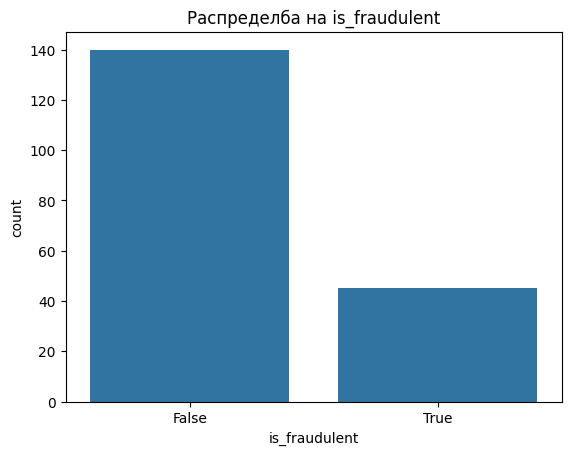

In [63]:
# Распределба на целната променлива
sns.countplot(x='is_fraudulent', data=df)
plt.title("Распределба на is_fraudulent")
plt.show()

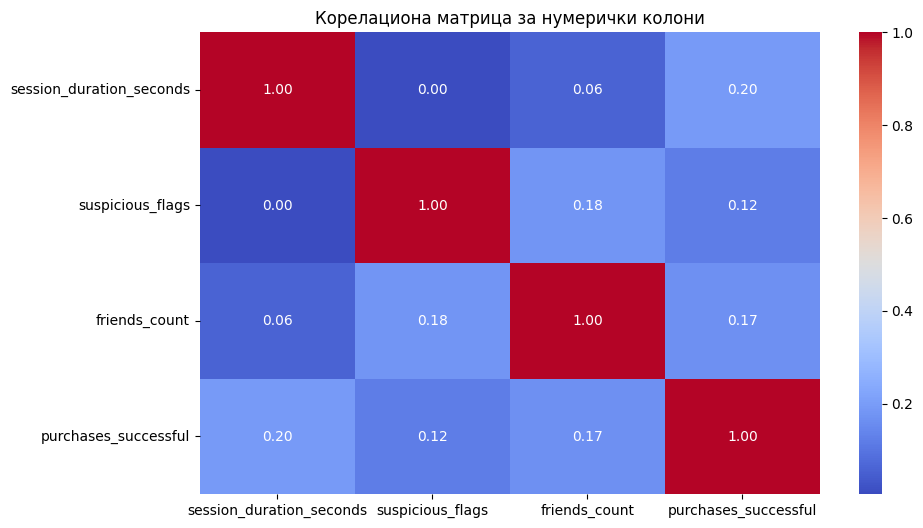

In [64]:
# Корелација помеѓу нумеричките колони
numeric_cols = df.select_dtypes(include=[np.number]).columns
plt.figure(figsize=(10, 6))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Корелациона матрица за нумерички колони")
plt.show()

In [65]:
# clicks колона
def parse_clicks(val):
    if pd.isna(val):
        return np.nan
    if '-' in str(val):
        parts = str(val).split('-')
        if len(parts) == 2:
            return (float(parts[0]) + float(parts[1])) / 2
    try:
        return float(val)
    except:
        return np.nan

df['clicks'] = df['clicks'].apply(parse_clicks)

In [66]:
# cpu_cores колона – издвојување број
df['cpu_cores'] = df['cpu_cores'].str.extract('(\d+)').astype(float)

In [67]:
# Пополнување на недостасувачки вредности
for col in df.columns:
    if df[col].dtype == 'object':
        df[col].fillna(df[col].mode()[0] if not df[col].mode().empty else "Unknown", inplace=True)
    else:
        df[col].fillna(df[col].median(), inplace=True)

In [68]:
from sklearn.preprocessing import LabelEncoder

le_dict = {}
categorical_cols = ['operating_system', 'browser', 'currency_code', 'chipset', 'chipset_manufacturer', 'accept_cookies']
for col in categorical_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col].astype(str))
    le_dict[col] = le

In [69]:
# IP колона – прв октет како груба локација
def first_octet(ip):
    if pd.isna(ip) or ip == "":
        return 0
    parts = str(ip).split('.')
    if len(parts) >= 1:
        return int(parts[0])
    return 0

df['ip_first_octet'] = df['ip_address'].apply(first_octet)
df.drop('ip_address', axis=1, inplace=True)

In [70]:
df['is_fraudulent'] = df['is_fraudulent'].astype(int)

In [71]:
from sklearn.model_selection import train_test_split

X = df.drop('is_fraudulent', axis=1)
y = df['is_fraudulent']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

In [72]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [73]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

In [74]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.711864406779661

Confusion Matrix:
[[42  3]
 [14  0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.93      0.83        45
           1       0.00      0.00      0.00        14

    accuracy                           0.71        59
   macro avg       0.38      0.47      0.42        59
weighted avg       0.57      0.71      0.63        59



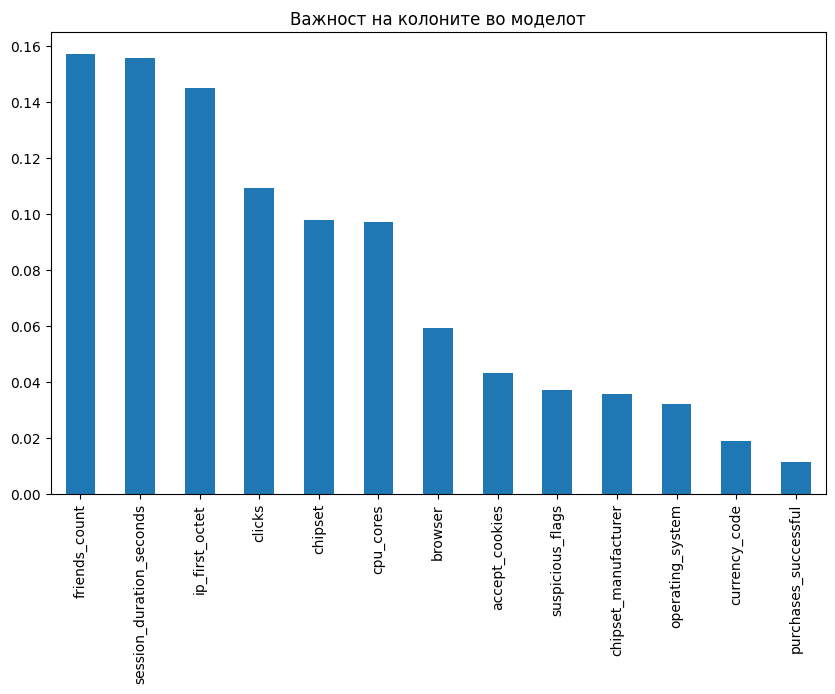

In [75]:
feature_importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(10, 6))
feature_importances.plot(kind='bar')
plt.title("Важност на колоните во моделот")
plt.show()